##  Project Overview

This project aims to detect fraudulent credit card transactions using **Logistic Regression**.

We build a complete machine learning pipeline including:
- Data exploration  
- Data preprocessing  
- Handling class imbalance  
- Model training  
- Model evaluation  

The goal is to accurately identify fraudulent transactions while minimizing false positives.

In [1]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler ,OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [2]:
import pandas as pd

df = pd.read_csv("hf://datasets/dazzle-nu/CIS435-CreditCardFraudDetection/fraudTrain.csv")


df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,Unnamed: 23,6006
0,0,1/1/19 0:00,2.703190e+15,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,3495,"Psychologist, counselling",3/9/88,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,NaN,NaN
1,1,1/1/19 0:00,6.304230e+11,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,149,Special educational needs teacher,6/21/78,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,NaN,NaN
2,2,1/1/19 0:00,3.885950e+13,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,4154,Nature conservation officer,1/19/62,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0,NaN,NaN
3,3,1/1/19 0:01,3.534090e+15,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,1939,Patent attorney,1/12/67,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0,NaN,NaN
4,4,1/1/19 0:03,3.755340e+14,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,99,Dance movement psychotherapist,3/28/86,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0,NaN,NaN


## Dataset Description



In [3]:
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,Unnamed: 23,6006
0,0,1/1/19 0:00,2.703190e+15,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,3495,"Psychologist, counselling",3/9/88,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,NaN,NaN
1,1,1/1/19 0:00,6.304230e+11,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,149,Special educational needs teacher,6/21/78,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,NaN,NaN
2,2,1/1/19 0:00,3.885950e+13,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,4154,Nature conservation officer,1/19/62,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0,NaN,NaN
3,3,1/1/19 0:01,3.534090e+15,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,1939,Patent attorney,1/12/67,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0,NaN,NaN
4,4,1/1/19 0:03,3.755340e+14,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,99,Dance movement psychotherapist,3/28/86,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0,NaN,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 25 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1048575 non-null  int64  
 1   trans_date_trans_time  1048575 non-null  str    
 2   cc_num                 1048575 non-null  float64
 3   merchant               1048575 non-null  str    
 4   category               1048575 non-null  str    
 5   amt                    1048575 non-null  float64
 6   first                  1048575 non-null  str    
 7   last                   1048575 non-null  str    
 8   gender                 1048575 non-null  str    
 9   street                 1048575 non-null  str    
 10  city                   1048575 non-null  str    
 11  state                  1048575 non-null  str    
 12  zip                    1048575 non-null  int64  
 13  lat                    1048575 non-null  float64
 14  long                   104857

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1048575.0,5.242870e+05,3.026977e+05,0.000000e+00,2.621435e+05,5.242870e+05,7.864305e+05,1.048574e+06
cc_num,1048575.0,4.171565e+17,1.308811e+18,6.041621e+10,1.800400e+14,3.520550e+15,4.642260e+15,4.992350e+18
amt,1048575.0,7.027910e+01,1.599518e+02,1.000000e+00,9.640000e+00,4.745000e+01,8.305000e+01,2.894890e+04
zip,1048575.0,4.880159e+04,2.689804e+04,1.257000e+03,2.623700e+04,4.817400e+04,7.204200e+04,9.978300e+04
lat,1048575.0,3.853336e+01,5.076852e+00,2.002710e+01,3.462050e+01,3.935430e+01,4.194040e+01,6.669330e+01
long,1048575.0,-9.022626e+01,1.375858e+01,-1.656723e+02,-9.679800e+01,-8.747690e+01,-8.015800e+01,-6.795030e+01
city_pop,1048575.0,8.905776e+04,3.024351e+05,2.300000e+01,7.430000e+02,2.456000e+03,2.032800e+04,2.906700e+06
unix_time,1048575.0,1.344906e+09,1.019700e+07,1.325376e+09,1.336682e+09,1.344902e+09,1.354366e+09,1.362932e+09
merch_lat,1048575.0,3.853346e+01,5.111233e+00,1.902779e+01,3.472954e+01,3.936295e+01,4.195602e+01,6.751027e+01
merch_long,1048575.0,-9.022648e+01,1.377093e+01,-1.666712e+02,-9.689864e+01,-8.743923e+01,-8.023228e+01,-6.695090e+01


In [6]:
df.dtypes

Unnamed: 0                 int64
trans_date_trans_time        str
cc_num                   float64
merchant                     str
category                     str
amt                      float64
first                        str
last                         str
gender                       str
street                       str
city                         str
state                        str
zip                        int64
lat                      float64
long                     float64
city_pop                   int64
job                          str
dob                          str
trans_num                    str
unix_time                  int64
merch_lat                float64
merch_long               float64
is_fraud                   int64
Unnamed: 23              float64
6006                     float64
dtype: object

##  EDA & Data Cleaning

In [7]:
df.drop(columns=['Unnamed: 0','cc_num','first', 'last', 'street', 'city', 'state', 'zip', 'dob', 'trans_num','trans_date_trans_time'],inplace=True)
df

,merchant,category,amt,gender,lat,long,city_pop,job,unix_time,merch_lat,merch_long,is_fraud,Unnamed: 23,6006
0,"fraud_Rippin, Kub and Mann",misc_net,4.97,F,36.0788,-81.1781,3495,"Psychologist, counselling",1325376018,36.011293,-82.048315,0,NaN,NaN
1,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,F,48.8878,-118.2105,149,Special educational needs teacher,1325376044,49.159047,-118.186462,0,NaN,NaN
2,fraud_Lind-Buckridge,entertainment,220.11,M,42.1808,-112.2620,4154,Nature conservation officer,1325376051,43.150704,-112.154481,0,NaN,NaN
3,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,M,46.2306,-112.1138,1939,Patent attorney,1325376076,47.034331,-112.561071,0,NaN,NaN
4,fraud_Keeling-Crist,misc_pos,41.96,M,38.4207,-79.4629,99,Dance movement psychotherapist,1325376186,38.674999,-78.632459,0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048570,fraud_Fadel Inc,health_fitness,77.00,F,39.0305,-76.5515,92106,"Accountant, chartered certified",1362931649,38.779464,-76.317042,0,NaN,NaN
1048571,"fraud_Cremin, Hamill and Reichel",misc_pos,116.94,F,41.1826,-92.3097,1583,Geochemist,1362931670,41.400318,-92.726724,0,NaN,NaN
1048572,"fraud_O'Connell, Botsford and Hand",home,21.27,F,38.2507,-85.7476,736284,Engineering geologist,1362931711,37.293339,-84.798122,0,NaN,NaN
1048573,fraud_Thompson-Gleason,health_fitness,9.52,F,40.7320,-73.1000,4056,Film/video editor,1362931718,39.773077,-72.213209,0,NaN,NaN


In [8]:
df.dropna(ignore_index=True)
df

,merchant,category,amt,gender,lat,long,city_pop,job,unix_time,merch_lat,merch_long,is_fraud,Unnamed: 23,6006
0,"fraud_Rippin, Kub and Mann",misc_net,4.97,F,36.0788,-81.1781,3495,"Psychologist, counselling",1325376018,36.011293,-82.048315,0,NaN,NaN
1,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,F,48.8878,-118.2105,149,Special educational needs teacher,1325376044,49.159047,-118.186462,0,NaN,NaN
2,fraud_Lind-Buckridge,entertainment,220.11,M,42.1808,-112.2620,4154,Nature conservation officer,1325376051,43.150704,-112.154481,0,NaN,NaN
3,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,M,46.2306,-112.1138,1939,Patent attorney,1325376076,47.034331,-112.561071,0,NaN,NaN
4,fraud_Keeling-Crist,misc_pos,41.96,M,38.4207,-79.4629,99,Dance movement psychotherapist,1325376186,38.674999,-78.632459,0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1048570,fraud_Fadel Inc,health_fitness,77.00,F,39.0305,-76.5515,92106,"Accountant, chartered certified",1362931649,38.779464,-76.317042,0,NaN,NaN
1048571,"fraud_Cremin, Hamill and Reichel",misc_pos,116.94,F,41.1826,-92.3097,1583,Geochemist,1362931670,41.400318,-92.726724,0,NaN,NaN
1048572,"fraud_O'Connell, Botsford and Hand",home,21.27,F,38.2507,-85.7476,736284,Engineering geologist,1362931711,37.293339,-84.798122,0,NaN,NaN
1048573,fraud_Thompson-Gleason,health_fitness,9.52,F,40.7320,-73.1000,4056,Film/video editor,1362931718,39.773077,-72.213209,0,NaN,NaN


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["is_fraud"].value_counts()


is_fraud
0    1042569
1       6006
Name: count, dtype: int64

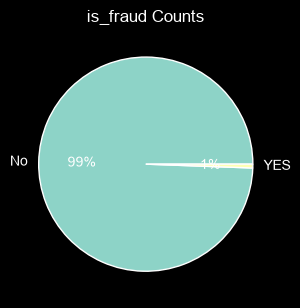

In [11]:
df["is_fraud"].value_counts()
plt.figure(figsize=(6,10))
plt.subplot(1, 2, 1)  

plt.pie(df["is_fraud"].value_counts() ,labels=["No", "YES"], autopct="%0.0f%%" )

plt.title("is_fraud Counts")
plt.tight_layout()
plt.show()



## Feature Scaling

In [12]:
categorical_cols = ['merchant', 'category', 'gender', 'job']
numeric_cols = ['amt', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long', 'unix_time']

In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OrdinalEncoder( handle_unknown='use_encoded_value',unknown_value=-1), categorical_cols)
    ])

##  Train Test Split



In [14]:
X = df.drop(columns=["is_fraud"], inplace = False)
Y = df["is_fraud"]

##  Model Training


In [15]:
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression())
])

In [16]:
model.fit(X, Y)


/Users/nimdulaperera/Documents/University/Fourth Year/Fall 2026/Machine Learning I/Unspupervised-Learning-For-Fraud-Detection_CSCI-3052U-Project/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['merchant','category','amt',...,'merch_long','Unnamed: 23','6006']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all

In [17]:
model.score(X, Y)


0.993725770688792

In [18]:
# Split into 80% training and 20% testing
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["is_fraud"]
)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)


Training shape: (838860, 14)
Testing shape: (209715, 14)


In [19]:
test_df.drop(columns=['Unnamed: 0','cc_num','first', 'last', 'street', 'city', 'state', 'zip', 'dob', 'trans_num','trans_date_trans_time'],inplace=True)
test_df

KeyError: "['Unnamed: 0', 'cc_num', 'first', 'last', 'street', 'city', 'state', 'zip', 'dob', 'trans_num', 'trans_date_trans_time'] not found in axis"

In [ ]:
X_test = test_df.drop(columns=["is_fraud"], inplace = False)
Y_test = test_df["is_fraud"]

In [ ]:
y_pred = model.predict(X_test)
y_pred

## Model Evaluation

In [ ]:
print("Accuracy:", accuracy_score(Y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(Y_test, y_pred))
print("\nClassification Report:\n", classification_report(Y_test, y_pred))